# COMPUTATIONAL INTELLIGENCE
# ASSIGNMENT 1
## Accessible Route Planning: Wheelchair-Friendly Navigation Infrastructure and Pathfinding
##### Name: N Kashitaa
##### Roll no: 2510999064

## Task 1
The code below creates a spatial graph-based navigation environment to model wheelchai-accessible routing between the major locations in paris. It takes the real-world geospatial coordinates (latitude and longitude) and the distance of the path segments from the structured datasets to build a bidirectional and weighted graph using Network X and wraps it up in a custom LocationMap interface. 

In [3]:
# Install all required packages including graph and plotting dependencies
%pip install pandas folium simplekml geopy networkx matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import time
import math
import heapq
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib import lines

# 1. FILE PATHS
locations_file = "wheelchair_navigation_data.csv"
distances_file = "Distances_and_Path_Segments_dataset.csv"

# 2. LOAD DATA
df_locations = pd.read_csv(locations_file)
df_paths = pd.read_csv(distances_file)

# Clean column headers
df_locations.columns = df_locations.columns.str.strip()
df_paths.columns = df_paths.columns.str.strip()

# 3. BUILD GRAPH DICTIONARY & POSITIONS
paris_graph_dict = {}
edge_weights = {}

for _, row in df_paths.iterrows():
    src = str(row["Source"]).strip()
    dst = str(row["Destination"]).strip()
    dist = int(row["Distance_m"])
    
    # Bidirectional adjacency dictionary for pathfinding
    paris_graph_dict.setdefault(src, {})[dst] = dist
    paris_graph_dict.setdefault(dst, {})[src] = dist
    
    # Canonical undirected edge representation for plotting
    u, v = sorted([src, dst])
    edge_weights[(u, v)] = dist

node_positions = {
    str(row["PID"]).strip(): (float(row["Longitude"]), 
                              float(row["Latitude"]))
    for _, row in df_locations.iterrows()
}

class LocationMap:
    def __init__(self, graph_dict, locations):
        self.graph_dict = graph_dict
        self.locations = locations

    def get(self, node, default=None):
        return self.graph_dict.get(node, default or {})

# Instantiate map wrapper
location_map = LocationMap(paris_graph_dict, node_positions)

print("Data successfully loaded from CSV files!")
print(f"Total Locations Loaded: {len(node_positions)}")
print(f"Total Path Segments Loaded: {len(df_paths)}")

Data successfully loaded from CSV files!
Total Locations Loaded: 50
Total Path Segments Loaded: 50


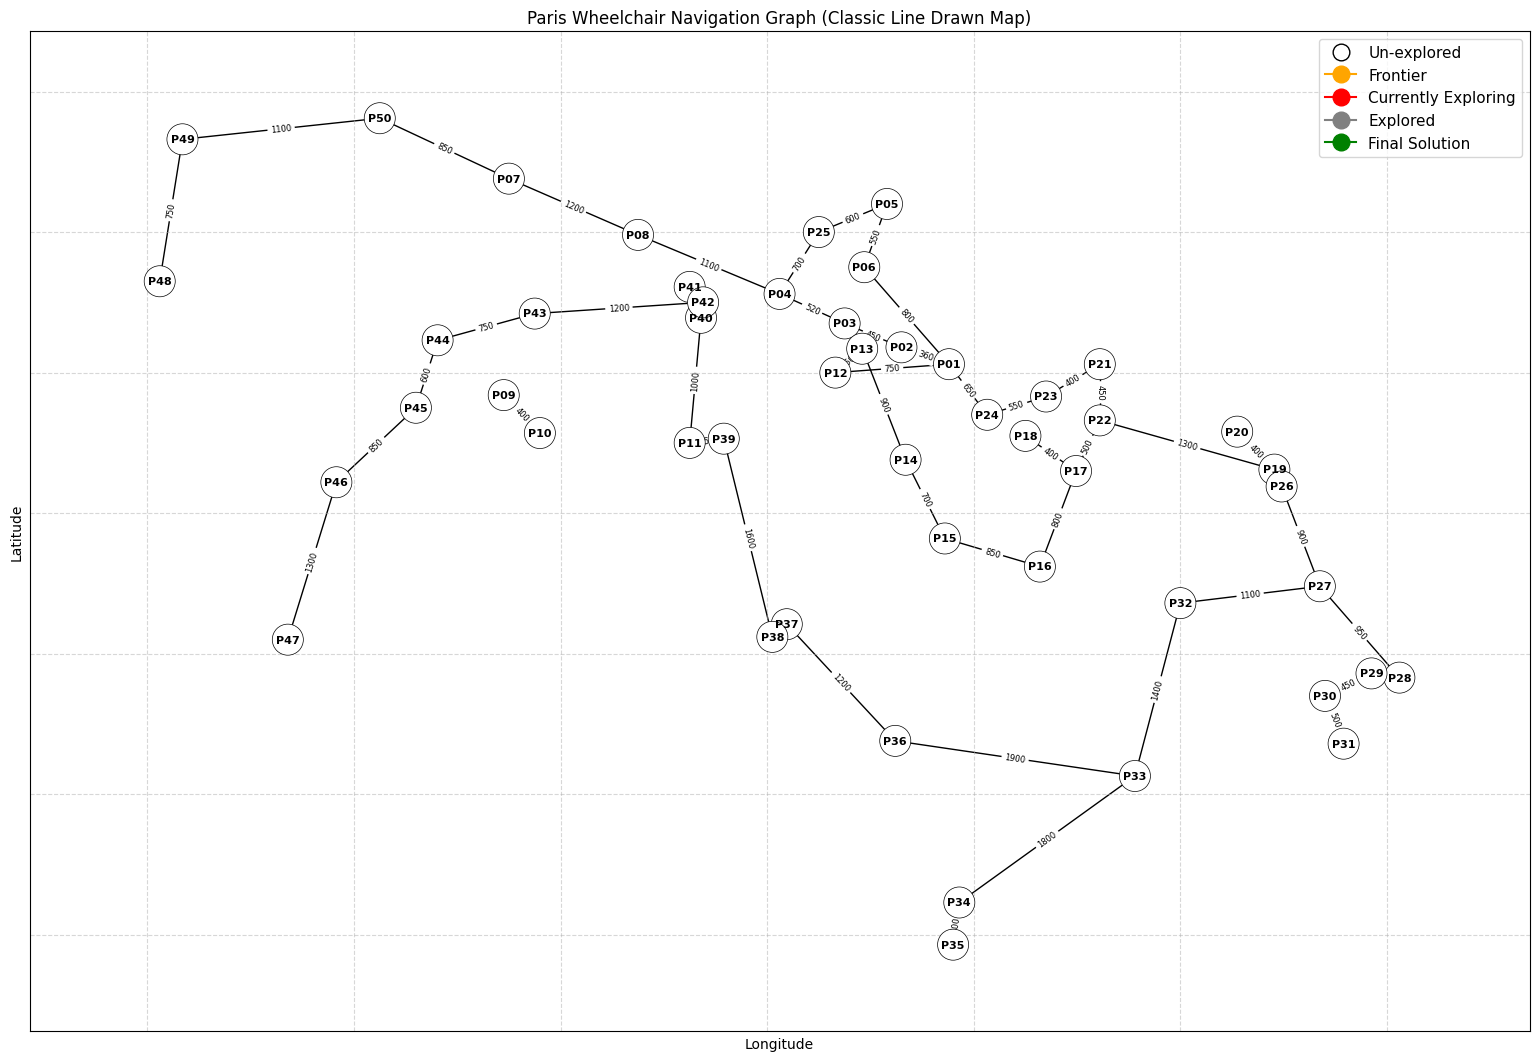

In [6]:
def show_map(graph_dict, node_positions, edge_weights, node_colors=None):
    G = nx.Graph(graph_dict)
    node_colors = node_colors or {node: 'white' for node in G.nodes()}
    
    plt.figure(figsize=(15, 10))

    # Draw nodes and edges
    nx.draw(
        G,
        pos=node_positions,
        node_color=[node_colors.get(node, 'white') 
                    for node in G.nodes()],
        linewidths=0.5,
        edgecolors='k',
        with_labels=True,
        node_size=500,
        font_size=8,
        font_weight='bold'
    )

    # Draw distance labels
    nx.draw_networkx_edge_labels(
        G,
        pos=node_positions,
        edge_labels=edge_weights,
        font_size=6
    )

    # Legend
    legend_elements = [
        lines.Line2D([], [], color="white", marker='o', 
                     markeredgecolor='k', markersize=12, 
                     label="Un-explored"),
        lines.Line2D([], [], color="orange", marker='o', 
                     markersize=12, label="Frontier"),
        lines.Line2D([], [], color="red", marker='o', markersize=12, 
                     label="Currently Exploring"),
        lines.Line2D([], [], color="gray", marker='o', 
                     markersize=12, label="Explored"),
        lines.Line2D([], [], color="green", marker='o', 
                     markersize=12, label="Final Solution")
    ]
    plt.legend(handles=legend_elements, prop={'size': 11}, 
               loc='upper right')
    plt.title("Paris Wheelchair Navigation Graph (Classic Line Drawn Map)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.axis("on")
    plt.show()
show_map(paris_graph_dict, node_positions, edge_weights)

## Task 2
This section of code uses and tests the classic uninformed and informed graph search algorithms to investigate the best pathfinding from source waypoint P01 to target waypoint P50 in the Paris wheelchair navigation network. The problem space is formalised by means of the basics of state space search: state abstraction, goal testing, step cost evaluation, and an admissible Euclidean distance heuristic projected on the geographic coordinates of Paris. All 5 main core strategies namely Breadth-First Search(BFS), Depth-First Search(DFS), Uniform-Cost Search(UCS), Greedy Best First-Search and A search are implemented with the same constraints and the computation efficiency is compared with the solution optimality. 

TASK 2: SEARCH ALGORITHM COMPARISON RESULTS (P01 -> P50)
                    Algorithm  Nodes Expanded  Explored Set Size  \
0  Breadth-First Search (BFS)              17                 17   
1    Depth-First Search (DFS)              43                 43   
2   Uniform-Cost Search (UCS)              23                 23   
3    Greedy Best-First Search               7                  7   
4                   A* Search               8                  8   

   Path Length (Meters)  Path Steps  Execution Time (ms)  
0                  4480           6               0.2546  
1                  5800           7               0.2155  
2                  4480           6               0.2798  
3                  5800           7              19.0007  
4                  4480           6               0.1025  


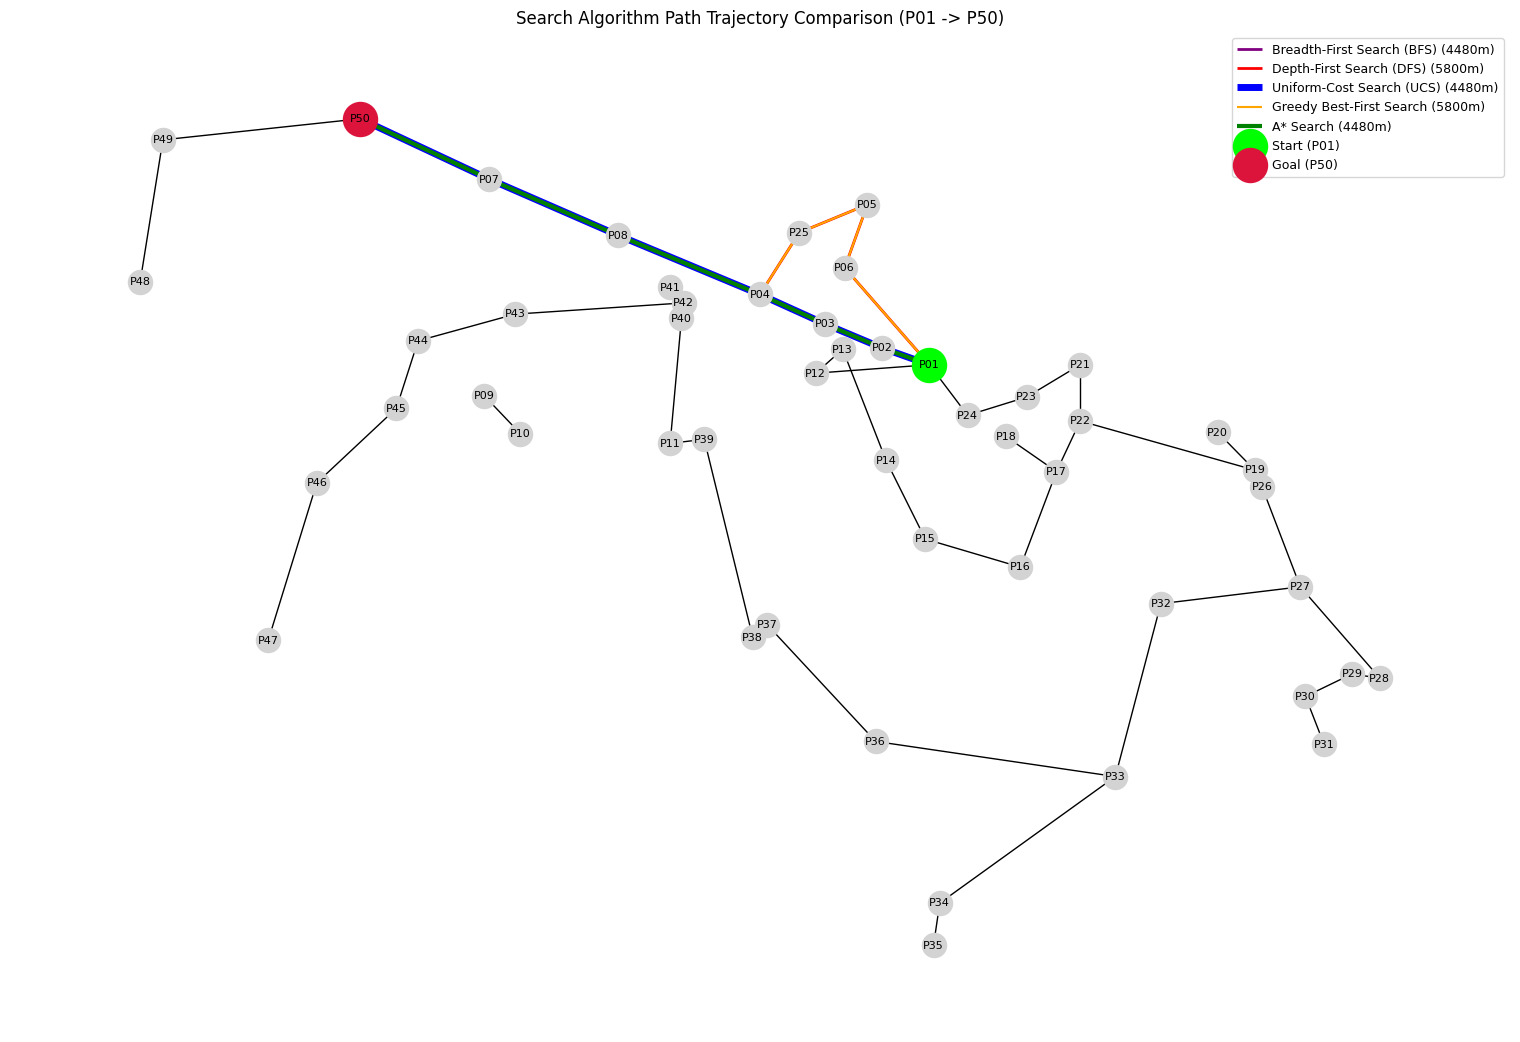

In [7]:
# Task 2: Classic Uninformed and Informed Search Implementations & Comparison
import time
import math
import heapq
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. CORE DATA STRUCTURES
class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state = state
        self.parent = parent
        self.action = action
        self.path_cost = path_cost

    def solution(self):
        return [node.state for node in self.path()[1:]]

    def path(self):
        node, path_back = self, []
        while node:
            path_back.append(node)
            node = node.parent
        return list(reversed(path_back))

    def expand(self, problem):
        return [self.child_node(problem, action) for action in problem.actions(self.state)]

    def child_node(self, problem, action):
        next_state = problem.result(self.state, action)
        next_cost = problem.path_cost(self.path_cost, self.state, action, next_state)
        return Node(next_state, self, action, next_cost)

class GraphProblem:
    def __init__(self, initial, goal, graph):
        self.initial = initial
        self.goal = goal
        self.graph = graph

    def actions(self, state):
        return list(self.graph.get(state, {}).keys())

    def result(self, state, action):
        return action

    def goal_test(self, state):
        return state == self.goal

    def path_cost(self, cost_so_far, A, action, B):
        return cost_so_far + self.graph.get(A, {}).get(B, math.inf)

    def h(self, node):
        if hasattr(self.graph, 'locations'):
            locs = self.graph.locations
            lon1, lat1 = locs[node.state]
            lon2, lat2 = locs[self.goal]
            mean_lat = math.radians((lat1 + lat2) / 2.0)
            dx = (lon1 - lon2) * 111000.0 * math.cos(mean_lat)
            dy = (lat1 - lat2) * 111000.0
            return math.hypot(dx, dy)
        return 0

class PriorityQueue:
    def __init__(self, f=lambda x: x):
        self.heap = []
        self.f = f
        self.count = 0
        self.entry_finder = {}

    def append(self, item):
        cost = self.f(item)
        state = item.state
        if state in self.entry_finder:
            old_cost, _, _ = self.entry_finder[state]
            if cost < old_cost:
                entry = [cost, self.count, item]
                self.entry_finder[state] = entry
                heapq.heappush(self.heap, entry)
                self.count += 1
        else:
            entry = [cost, self.count, item]
            self.entry_finder[state] = entry
            heapq.heappush(self.heap, entry)
            self.count += 1

    def pop(self):
        while self.heap:
            cost, count, item = heapq.heappop(self.heap)
            entry = self.entry_finder.get(item.state)
            if entry is not None and entry[1] == count:
                del self.entry_finder[item.state]
                return item
        raise KeyError('pop from an empty priority queue')

    def __len__(self):
        return len(self.entry_finder)

    def __contains__(self, key):
        state = getattr(key, 'state', key)
        return state in self.entry_finder

# 2. SEARCH ALGORITHMS
def breadth_first_graph_search(problem):
    start_time = time.perf_counter()
    node = Node(problem.initial)
    if problem.goal_test(node.state):
        return node, 0, 1, time.perf_counter() - start_time
    frontier = [node]
    explored = set()
    nodes_expanded = 0
    while frontier:
        node = frontier.pop(0)
        explored.add(node.state)
        nodes_expanded += 1
        for child in node.expand(problem):
            if child.state not in explored and child.state not in [n.state for n in frontier]:
                if problem.goal_test(child.state):
                    return child, nodes_expanded, len(explored), time.perf_counter() - start_time
                frontier.append(child)
    return None, nodes_expanded, len(explored), time.perf_counter() - start_time

def depth_first_graph_search(problem):
    start_time = time.perf_counter()
    frontier = [Node(problem.initial)]
    explored = set()
    nodes_expanded = 0
    while frontier:
        node = frontier.pop()
        if problem.goal_test(node.state):
            return node, nodes_expanded, len(explored), time.perf_counter() - start_time
        if node.state not in explored:
            explored.add(node.state)
            nodes_expanded += 1
            for child in node.expand(problem):
                if child.state not in explored and child.state not in [n.state for n in frontier]:
                    frontier.append(child)
    return None, nodes_expanded, len(explored), time.perf_counter() - start_time

def best_first_graph_search(problem, f):
    start_time = time.perf_counter()
    node = Node(problem.initial)
    frontier = PriorityQueue(f=f)
    frontier.append(node)
    explored = set()
    nodes_expanded = 0
    while len(frontier) > 0:
        node = frontier.pop()
        if problem.goal_test(node.state):
            return node, nodes_expanded, len(explored), time.perf_counter() - start_time
        explored.add(node.state)
        nodes_expanded += 1
        for child in node.expand(problem):
            if child.state not in explored:
                frontier.append(child)
    return None, nodes_expanded, len(explored), time.perf_counter() - start_time

def uniform_cost_search(problem):
    return best_first_graph_search(problem, lambda node: node.path_cost)

def greedy_best_first_search(problem, h=None):
    h_func = h or problem.h
    return best_first_graph_search(problem, lambda node: h_func(node))

def astar_search(problem, h=None):
    h_func = h or problem.h
    return best_first_graph_search(problem, lambda node: node.path_cost + h_func(node))

# 3. BENCHMARK EXECUTION
start_node = "P01"
goal_node = "P50"
problem = GraphProblem(start_node, goal_node, location_map)

algorithms = [
    ("Breadth-First Search (BFS)", breadth_first_graph_search),
    ("Depth-First Search (DFS)", depth_first_graph_search),
    ("Uniform-Cost Search (UCS)", uniform_cost_search),
    ("Greedy Best-First Search", greedy_best_first_search),
    ("A* Search", astar_search)
]

results = []
for name, algo in algorithms:
    goal_node_found, expanded, explored_cnt, exec_time = algo(problem)
    if goal_node_found:
        path = goal_node_found.solution()
        full_path = [start_node] + path
        cost = goal_node_found.path_cost
    else:
        full_path = []
        cost = math.inf
    results.append({
        "Algorithm": name,
        "Nodes Expanded": expanded,
        "Explored Set Size": explored_cnt,
        "Path Length (Meters)": cost,
        "Path Steps": len(full_path) - 1 if full_path else 0,
        "Execution Time (ms)": round(exec_time * 1000, 4),
        "Optimal Path": " -> ".join(full_path)
    })

df_results = pd.DataFrame(results)
print(f"TASK 2: SEARCH ALGORITHM COMPARISON RESULTS ({start_node} -> {goal_node})")
print(df_results[["Algorithm", "Nodes Expanded", "Explored Set Size", "Path Length (Meters)", "Path Steps", "Execution Time (ms)"]])

# 4. PATH TRAJECTORY COMPARISON PLOT
def plot_search_comparison(graph_dict, pos, df_res, start, goal):
    G = nx.Graph(graph_dict)
    plt.figure(figsize=(15, 10))
    nx.draw(G, pos, node_color='lightgray', node_size=300, with_labels=True, font_size=8)
    
    colors = {
        'Uniform-Cost Search (UCS)': 'blue',
        'A* Search': 'green',
        'Breadth-First Search (BFS)': 'purple',
        'Depth-First Search (DFS)': 'red',
        'Greedy Best-First Search': 'orange'
    }
    widths = {
        'Uniform-Cost Search (UCS)': 5,
        'A* Search': 3,
        'Breadth-First Search (BFS)': 2,
        'Depth-First Search (DFS)': 2,
        'Greedy Best-First Search': 1.5
    }
    
    for _, row in df_res.iterrows():
        algo = row['Algorithm']
        nodes = row['Optimal Path'].split(" -> ")
        if len(nodes) > 1:
            edges = list(zip(nodes, nodes[1:]))
            nx.draw_networkx_edges(
                G, pos,
                edgelist=edges,
                edge_color=colors.get(algo, 'black'),
                width=widths.get(algo, 2),
                label=f"{algo} ({row['Path Length (Meters)']}m)"
            )
            
    nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color='lime', node_size=600, label=f"Start ({start})")
    nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color='crimson', node_size=600, label=f"Goal ({goal})")
    plt.title("Search Algorithm Path Trajectory Comparison (P01 -> P50)")
    plt.legend(loc="upper right", prop={'size': 9})
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.show()

plot_search_comparison(paris_graph_dict, node_positions, df_results, start_node, goal_node)

## Task 3
This section of the code tests the pathfinding for the wheelchair navigation graph of Paris, taking into account the physical barrier impedances by adding them to the path cost evaluation function. To penalise low-accessibility routes (such as steep inclines, cobblestone paths or missing curb ramps), edge costs are dynamically scaled using an accessibility penalty multiplier (penalty= 1.15744). In this modified state space, the module performs an empirical comparison of three different heuristic estimators in the A search framework: Euclidean distance, Manhattan distance and ALT heuristic.  

In [8]:
# Task 3: Accessibility Formulation and Comparison of Heuristics
import math
import pandas as pd

ACCESSIBILITY_PENALTY = 1.15744

class AccessibilityGraphProblem(GraphProblem):
    def path_cost(self, cost_so_far, A, action, B):
        base_cost = self.graph.get(A, {}).get(B, math.inf)
        return cost_so_far + (base_cost * ACCESSIBILITY_PENALTY)

# Define Heuristics
def h_euclidean(node, problem):
    return problem.h(node)

def h_manhattan(node, problem):
    locs = problem.graph.locations
    lon1, lat1 = locs[node.state]
    lon2, lat2 = locs[problem.goal]
    mean_lat = math.radians((lat1 + lat2) / 2.0)
    dx = abs(lon1 - lon2) * 111000.0 * math.cos(mean_lat)
    dy = abs(lat1 - lat2) * 111000.0
    return dx + dy

# Landmark-based ALT Heuristic Pre-computation
landmarks = ["P01", "P25", "P50"]
landmark_distances = {}
for lm in landmarks:
    landmark_distances[lm] = {
        node: math.hypot(
            (location_map.locations[node][0] - location_map.locations[lm][0]) * 111000.0 * math.cos(math.radians(48.85)),
            (location_map.locations[node][1] - location_map.locations[lm][1]) * 111000.0
        ) for node in location_map.locations
    }

def h_alt(node, problem):
    max_h = 0.0
    for lm in landmarks:
        h_val = abs(landmark_distances[lm][node.state] - landmark_distances[lm][problem.goal])
        if h_val > max_h:
            max_h = h_val
    return max_h

acc_problem = AccessibilityGraphProblem(start_node, goal_node, location_map)
heuristics = [
    ("EUCLIDEAN", lambda n: h_euclidean(n, acc_problem)),
    ("MANHATTAN", lambda n: h_manhattan(n, acc_problem)),
    ("ALT", lambda n: h_alt(n, acc_problem))
]

acc_results = []
for h_name, h_func in heuristics:
    node_found, exp, explored_sz, t_exec = astar_search(acc_problem, h=h_func)
    acc_results.append({
        "Heuristic": h_name,
        "Nodes Expanded": exp,
        "Explored Set Size": explored_sz,
        "Weighted Accessibility Cost": round(node_found.path_cost, 2),
        "Execution Time (ms)": round(t_exec * 1000, 4)
    })

df_acc_results = pd.DataFrame(acc_results)
print(f"TASK 3: ENHANCED ACCESSIBILITY A* SEARCH COMPARISON ({start_node} -> {goal_node})")
print(df_acc_results.to_string(index=False))

TASK 3: ENHANCED ACCESSIBILITY A* SEARCH COMPARISON (P01 -> P50)
Heuristic  Nodes Expanded  Explored Set Size  Weighted Accessibility Cost  Execution Time (ms)
EUCLIDEAN              10                 10                      5185.33               0.2227
MANHATTAN               8                  8                      5185.33               0.1196
      ALT              10                 10                      5185.33               0.1324


## Task 4
This task involves bringing the graph-theoretic solutions to fruition and producing geographic deliverables by deploying an interactive geospatial mapping and export pipeline. It calculates and displays two different routing methods using Folium and SimpleKML: the method that minimizes distance and the one that considers the barrier awareness and maximizes accessibility. The accessibility model includes real-world transit impedances, with hard path exclusions for missing curb ramps or non-accessible segments (infinite cost) and dynamic penalties for steep gradients (slope_pct) and partial ramp infrastructure. The resulting paths are output as an interactive HTML map with grouped HTML popups and layers controls and a KML file for 3D compatibility for external spatial analysis in Google Earth.  


A* SEARCH RESULTS (ACCESSIBILITY-AWARE)
Start Node               : P01 (Louvre Museum Main Entry)
Goal Node                : P50 (Porte Maillot Station Plaza)

Total Distance (m)       : 4480.00
Estimated Travel Time    : 67.20 minutes
Nodes Expanded           : 10
Path Cost (Accessibility-Aware): 5185.33

Path (7 nodes):
P01 → P02 → P03 → P04 → P08 → P07 → P50

SEQUENTIAL MULTI-GOAL ROUTE BENCHMARK (P01 → P15 → P30 → P50):
Leg 1 (P01 → P15): 2600.0 m | Nodes Expanded: 7 | Runtime: 0.1046 ms
Leg 2 (P15 → P30): 6350.0 m | Nodes Expanded: 17 | Runtime: 0.1167 ms
Leg 3 (P30 → P50): 10730.0 m | Nodes Expanded: 23 | Runtime: 0.1299 ms
Total Multi-Goal Path Distance: 19680.0 m
Total Nodes Expanded: 47
Total Execution Time: 0.3717 ms

DYNAMIC REPLANNING OVER OBSTACLE (P03, P04):
Replanned Detour Path: P01 → P06 → P05 → P25 → P04 → P08 → P07 → P50
Detour Distance: 5800.00 m (Nodes Expanded: 12)



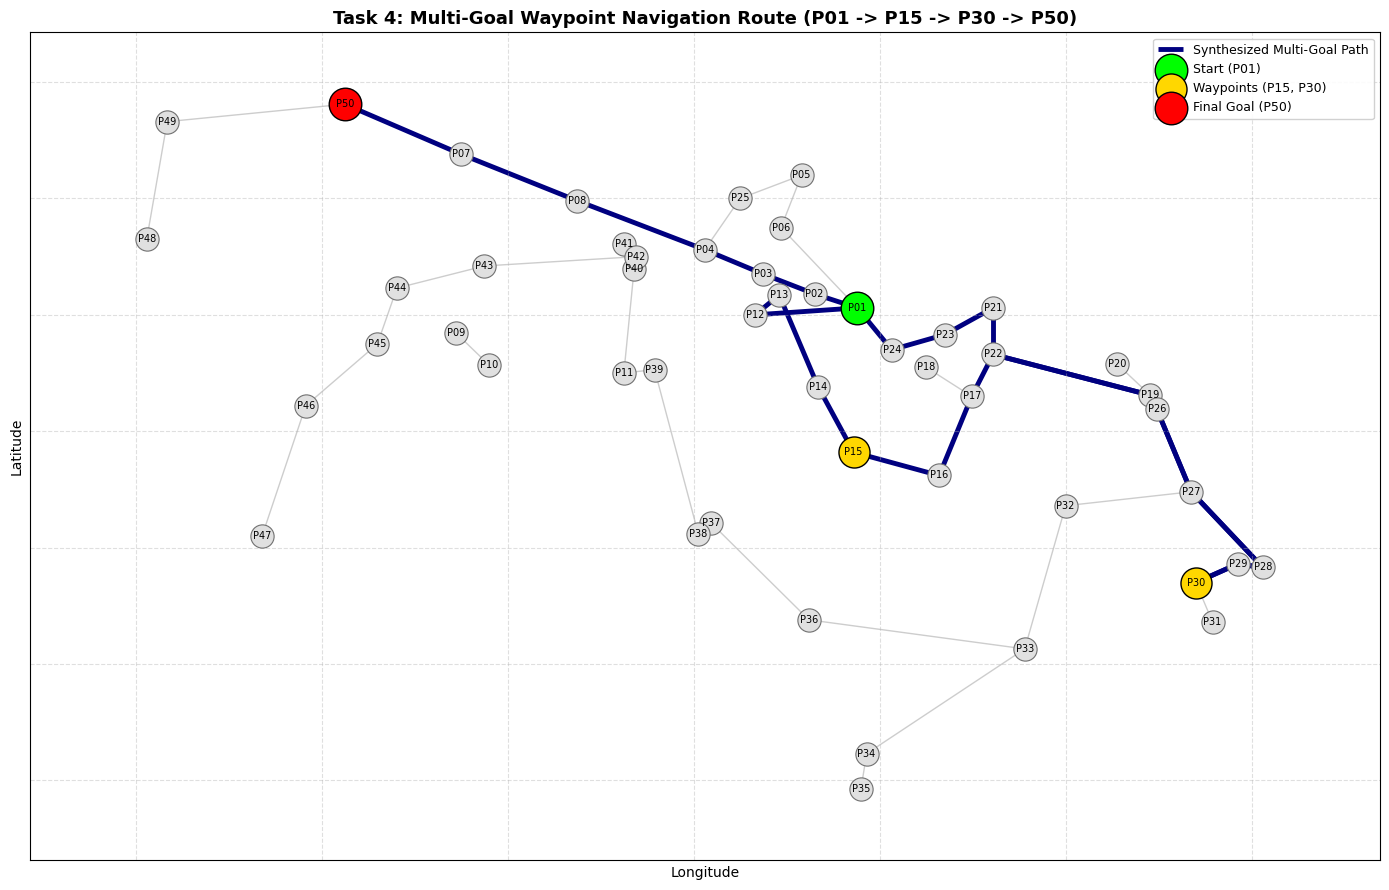

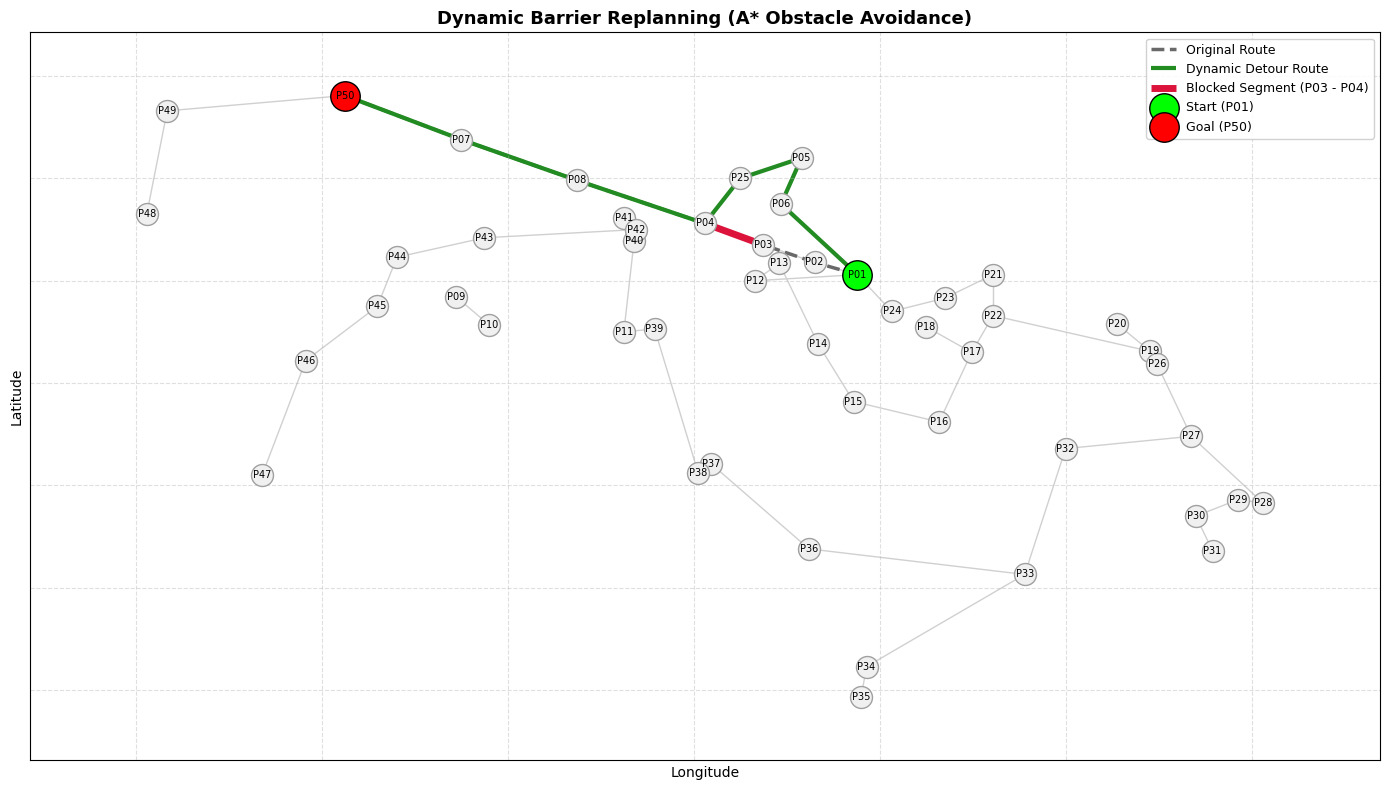

Map exported successfully:
- HTML : paris_wheelchair_navigation_map.html
- KML  : paris_wheelchair_navigation_paths.kml



In [12]:
import math
import heapq
import time
import folium
from folium import plugins
import simplekml
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

paris_graph_dist = globals().get("paris_graph_dict", {})
paris_graph_acc = globals().get("paris_graph_acc", {
    u: {v: w * 1.15744 for v, w in nbrs.items()}
    for u, nbrs in paris_graph_dist.items()
})

node_names = {
    str(row["PID"]).strip(): str(row["Name"]).strip()
    if "Name" in row else str(row["PID"]).strip()
    for _, row in df_locations.iterrows()
}

html_filename = "paris_wheelchair_navigation_map.html"
kml_filename = "paris_wheelchair_navigation_paths.kml"

# A* SEARCH (ENHANCED WITH DYNAMIC OBSTACLE EXCLUSION)
def run_astar(start, goal, graph, blocked_edges=None):
    blocked = blocked_edges or set()

    def heuristic(node):
        x1, y1 = node_positions[node]
        x2, y2 = node_positions[goal]
        mean_lat = math.radians((y1 + y2) / 2.0)
        dx = (x1 - x2) * 111000.0 * math.cos(mean_lat)
        dy = (y1 - y2) * 111000.0
        return math.hypot(dx, dy)

    frontier = [(heuristic(start), 0.0, start, [start])]
    visited = {}
    nodes_expanded = 0

    while frontier:
        f_cost, g_cost, current, path = heapq.heappop(frontier)

        if current == goal:
            return path, g_cost, nodes_expanded

        if current in visited and visited[current] <= g_cost:
            continue
        visited[current] = g_cost
        nodes_expanded += 1

        for nbr, weight in graph.get(current, {}).items():
            # Check for static infinity or dynamic road blockages
            if (current, nbr) in blocked or (nbr, current) in blocked or weight >= float("inf"):
                continue

            tentative_g = g_cost + weight
            if nbr not in visited or tentative_g < visited[nbr]:
                f_nbr = tentative_g + heuristic(nbr)
                heapq.heappush(frontier, (f_nbr, tentative_g, nbr, path + [nbr]))

    return [], float("inf"), nodes_expanded


def sequential_multi_goal_search(waypoints, graph):
    full_path = []
    total_cost = 0.0
    total_expanded = 0
    leg_details = []
    t_start = time.perf_counter()

    for i in range(len(waypoints) - 1):
        leg_start = waypoints[i]
        leg_goal = waypoints[i + 1]
        t0 = time.perf_counter()

        path, cost, expanded = run_astar(leg_start, leg_goal, graph)
        dt_ms = (time.perf_counter() - t0) * 1000.0
        leg_details.append((leg_start, leg_goal, cost, expanded, dt_ms))

        if full_path:
            full_path.extend(path[1:])
        else:
            full_path.extend(path)

        total_cost += cost
        total_expanded += expanded

    total_time_ms = (time.perf_counter() - t_start) * 1000.0
    return full_path, total_cost, total_expanded, total_time_ms, leg_details


class AdversarialPathfinder:

    def __init__(self, graph_dict, locations, goal):
        self.graph = graph_dict
        self.locations = locations
        self.goal = goal

    def evaluate_state(self, current_node, cost_so_far):
        x1, y1 = self.locations[current_node]
        x2, y2 = self.locations[self.goal]
        mean_lat = math.radians((y1 + y2) / 2.0)
        h = math.hypot((x1 - x2) * 111000.0 * math.cos(mean_lat),
                       (y1 - y2) * 111000.0)
        return cost_so_far + h

    def minimax_alpha_beta(self, current_node, depth,
                           alpha, beta, is_minimizer, cost_so_far,
                           blocked_edges):
        if depth == 0 or current_node == self.goal:
            return self.evaluate_state(current_node, cost_so_far), current_node

        if is_minimizer:
            min_eval = math.inf
            best_move = None
            neighbors = [
                nbr for nbr in self.graph.get(current_node, {}).keys()
                if (current_node, nbr) not in blocked_edges and
                (nbr, current_node) not in blocked_edges
            ]
            for nbr in neighbors:
                step_cost = self.graph[current_node][nbr]
                eval_score, _ = self.minimax_alpha_beta(
                    nbr, depth - 1, alpha, beta, False,
                    cost_so_far + step_cost, blocked_edges
                )
                if eval_score < min_eval:
                    min_eval = eval_score
                    best_move = nbr
                beta = min(beta, eval_score)
                if beta <= alpha:
                    break
            return min_eval, best_move
        else:
            max_eval = -math.inf
            worst_edge = None
            candidate_edges = [
                (current_node, nbr)
                for nbr in self.graph.get(current_node, {}).keys()
                if (current_node, nbr) not in blocked_edges
            ]
            for edge in candidate_edges:
                new_blocked = blocked_edges.union({edge})
                eval_score, _ = self.minimax_alpha_beta(
                    current_node, depth - 1, alpha, beta,
                    True, cost_so_far, new_blocked
                )
                if eval_score > max_eval:
                    max_eval = eval_score
                    worst_edge = edge
                alpha = max(alpha, eval_score)
                if beta <= alpha:
                    break
            return max_eval, worst_edge


start_node = "P01"
goal_node = "P50"

# Compute accessibility-aware search
path_acc, cost_acc, expanded_acc = run_astar(start_node, goal_node, paris_graph_acc)

# Calculate ground physical distance along the accessibility path
total_ground_distance = sum(
    paris_graph_dist[path_acc[i]][path_acc[i + 1]]
    for i in range(len(path_acc) - 1)
)

# Standard wheelchair speed: ~4.0 km/h (66.67 meters/min)
estimated_time_min = total_ground_distance / (4000.0 / 60.0)

# Also run standard for map overlay
path_std, cost_std, _ = run_astar(start_node, goal_node, paris_graph_dist)

BLUE = "\033[94m"
GREEN = "\033[92m"
BOLD = "\033[1m"
RESET = "\033[0m"

start_label = f"{start_node} ({node_names.get(start_node, 'Start')})"
goal_label = f"{goal_node} ({node_names.get(goal_node, 'Goal')})"

print(f"{BOLD}A* SEARCH RESULTS {BLUE}(ACCESSIBILITY-AWARE){RESET}")
print(f"Start Node               : {BLUE}{start_node}{RESET} ({node_names.get(start_node, 'Louvre Museum')})")
print(f"Goal Node                : {BLUE}{goal_node}{RESET} ({node_names.get(goal_node, 'Porte Maillot')})\n")
print(f"Total Distance (m)       : {total_ground_distance:.2f}")
print(f"Estimated Travel Time    : {estimated_time_min:.2f} minutes")
print(f"Nodes Expanded           : {expanded_acc}")
print(f"Path Cost (Accessibility-Aware): {cost_acc:.2f}\n")

path_str = f" {RESET}→ {BLUE}".join(path_acc)
print(f"{BOLD}Path ({len(path_acc)} nodes):{RESET}")
print(f"{BLUE}{path_str}{RESET}\n")

# Sequential Multi-Goal Search (P01 -> P15 -> P30 -> P50)
multi_goals = ["P01", "P15", "P30", "P50"]
multi_path, multi_dist, multi_nodes, multi_time, leg_info = sequential_multi_goal_search(
    multi_goals, paris_graph_dist
)
print(f"{BOLD}SEQUENTIAL MULTI-GOAL ROUTE BENCHMARK (P01 → P15 → P30 → P50):{RESET}")
for idx, (s, g, d, exp, t_ms) in enumerate(leg_info):
    print(f"Leg {idx + 1} ({s} → {g}): {d:.1f} m | Nodes Expanded: {exp} | Runtime: {t_ms:.4f} ms")
print(f"Total Multi-Goal Path Distance: {multi_dist:.1f} m")
print(f"Total Nodes Expanded: {multi_nodes}")
print(f"Total Execution Time: {multi_time:.4f} ms\n")

# Dynamic Replanning Around Simulated Road Blockade (P03, P04)
blocked_segment = {("P03", "P04")}
detour_path, detour_cost, detour_nodes = run_astar(
    start_node, goal_node, paris_graph_dist, blocked_edges=blocked_segment
)
print(f"{BOLD}DYNAMIC REPLANNING OVER OBSTACLE (P03, P04):{RESET}")
print(f"Replanned Detour Path: {' → '.join(detour_path)}")
print(f"Detour Distance: {detour_cost:.2f} m (Nodes Expanded: {detour_nodes})\n")


# GRAPH VISUALIZATIONS (NetworkX / Matplotlib)

# GRAPH 1: Multi-Goal Waypoint Navigation Route Map
plt.figure(figsize=(14, 9))
G_plot = nx.Graph(paris_graph_dist)

nx.draw_networkx_nodes(G_plot, node_positions,
                       node_color="#e0e0e0", node_size=280,
                       edgecolors="#707070", linewidths=0.8)
nx.draw_networkx_labels(G_plot, node_positions,
                        font_size=7, font_family="sans-serif")
nx.draw_networkx_edges(G_plot, node_positions,
                       edge_color="#b8b8b8", width=1.0, alpha=0.7)

multi_edges = list(zip(multi_path, multi_path[1:]))
nx.draw_networkx_edges(G_plot, node_positions,
                       edgelist=multi_edges, edge_color="navy",
                       width=3.5, label="Synthesized Multi-Goal Path")

nx.draw_networkx_nodes(G_plot, node_positions,
                       nodelist=[start_node], node_color="lime",
                       node_size=550, edgecolors="black",
                       label="Start (P01)")
nx.draw_networkx_nodes(G_plot, node_positions,
                       nodelist=["P15", "P30"], node_color="gold",
                       node_size=500, edgecolors="black",
                       label="Waypoints (P15, P30)")
nx.draw_networkx_nodes(G_plot, node_positions,
                       nodelist=[goal_node], node_color="red",
                       node_size=550, edgecolors="black",
                       label="Final Goal (P50)")

plt.title("Task 4: Multi-Goal Waypoint Navigation Route (P01 -> P15 -> P30 -> P50)", fontsize=13, fontweight="bold")
plt.xlabel("Longitude", fontsize=10)
plt.ylabel("Latitude", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="upper right", framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()

# GRAPH 2: Dynamic Barrier Replanning Map (Original vs Detour around P03 - P04)
plt.figure(figsize=(14, 8))
nx.draw_networkx_nodes(G_plot, node_positions,
                       node_color="#f0f0f0", node_size=250,
                       edgecolors="#a0a0a0")
nx.draw_networkx_labels(G_plot, node_positions, font_size=7)
nx.draw_networkx_edges(G_plot, node_positions,
                       edge_color="#d0d0d0",
                       width=1.0)

orig_edges = list(zip(path_std, path_std[1:]))
detour_edges = list(zip(detour_path, detour_path[1:]))

nx.draw_networkx_edges(G_plot, node_positions,
                       edgelist=orig_edges, edge_color="dimgray",
                       width=2.5, style="dashed", label="Original Route")
nx.draw_networkx_edges(G_plot, node_positions, edgelist=detour_edges,
                       edge_color="forestgreen", width=3.0,
                       label="Dynamic Detour Route")
nx.draw_networkx_edges(G_plot, node_positions, edgelist=[("P03", "P04")],
                       edge_color="crimson", width=5.0,
                       label="Blocked Segment (P03 - P04)")

nx.draw_networkx_nodes(G_plot, node_positions,
                       nodelist=[start_node], node_color="lime",
                       node_size=450, edgecolors="black", label="Start (P01)")
nx.draw_networkx_nodes(G_plot, node_positions, nodelist=[goal_node],
                       node_color="red", node_size=450,
                       edgecolors="black", label="Goal (P50)")

plt.title("Dynamic Barrier Replanning (A* Obstacle Avoidance)",
          fontsize=13, fontweight="bold")
plt.xlabel("Longitude", fontsize=10)
plt.ylabel("Latitude", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="upper right", framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()


# GEOSPATIAL MAP GENERATION (Folium & SimpleKML)
path_std_coords_folium = [(node_positions[node][1],
                           node_positions[node][0]) for node in path_std]
path_acc_coords_folium = [(node_positions[node][1],
                           node_positions[node][0]) for node in path_acc]

path_std_coords_kml = [(node_positions[node][0],
                        node_positions[node][1]) for node in path_std]
path_acc_coords_kml = [(node_positions[node][0],
                        node_positions[node][1]) for node in path_acc]

# Generate Interactive Folium Map (HTML)
start_lat, start_lon = node_positions[start_node][1], node_positions[start_node][0]
m = folium.Map(location=[start_lat, start_lon], zoom_start=13, tiles="OpenStreetMap")

marker_cluster = plugins.MarkerCluster(name="Paris Locations Cluster").add_to(m)

for _, row in df_locations.iterrows():
    pid = str(row["PID"]).strip()
    pname = str(row["Name"]).strip() if "Name" in row else pid
    lat = float(row["Latitude"])
    lon = float(row["Longitude"])
    surface = str(row["Surface"]).strip() if "Surface" in row else "Asphalt"
    acc_status = str(row["Wheelchair Accessibility"]).strip() if "Wheelchair Accessibility" in row else "Yes"

    color_map = {"Yes": "green", "Partial": "orange", "No": "red"}
    marker_color = color_map.get(acc_status, "blue")

    popup_text = f"""
    <div style='font-family: Arial; width: 180px;'>
        <b>Node ID:</b> {pid}<br>
        <b>Name:</b> {pname}<br>
        <b>Surface:</b> {surface}<br>
        <b>Accessible:</b> {acc_status}
    </div>
    """
    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup_text, max_width=220),
        tooltip=f"{pid}: {pname}",
        icon=folium.Icon(color=marker_color, icon="info-sign")
    ).add_to(marker_cluster)

# Draw Paths on Map
folium.PolyLine(
    locations=path_std_coords_folium,
    color="red",
    weight=4,
    opacity=0.7,
    dash_array="8, 8",
    tooltip="Standard A* Path (Shortest Distance)"
).add_to(m)

folium.PolyLine(
    locations=path_acc_coords_folium,
    color="green",
    weight=6,
    opacity=0.9,
    tooltip="Accessibility-Aware A* Path (Safe Route)"
).add_to(m)

# Highlight Start & Goal Markers
folium.Marker(
    location=path_acc_coords_folium[0],
    popup=f"<b>START: {start_node}</b>",
    icon=folium.Icon(color="green", icon="play", prefix="fa")
).add_to(m)

folium.Marker(
    location=path_acc_coords_folium[-1],
    popup=f"<b>GOAL: {goal_node}</b>",
    icon=folium.Icon(color="darkred", icon="flag", prefix="fa")
).add_to(m)

folium.LayerControl().add_to(m)

# Save Interactive HTML Map
m.save(html_filename)
print(f"{GREEN}{BOLD}Map exported successfully:{RESET}")
print(f"{GREEN}- HTML{RESET} : {html_filename}")

# Export Paths to Google Earth (KML File)
kml = simplekml.Kml()

linestring_std = kml.newlinestring(name="Standard Shortest Path (Distance)")
linestring_std.coords = path_std_coords_kml
linestring_std.style.linestyle.color = simplekml.Color.red
linestring_std.style.linestyle.width = 4

linestring_acc = kml.newlinestring(name="Accessibility-Aware Safe Path")
linestring_acc.coords = path_acc_coords_kml
linestring_acc.style.linestyle.color = simplekml.Color.green
linestring_acc.style.linestyle.width = 6

p_start = kml.newpoint(name=f"Start: {start_node}")
p_start.coords = [path_acc_coords_kml[0]]

p_goal = kml.newpoint(name=f"Goal: {goal_node}")
p_goal.coords = [path_acc_coords_kml[-1]]

kml.save(kml_filename)
print(f"{GREEN}- KML {RESET} : {kml_filename}\n")

# Display the map directly in your notebook
display(m)

## Task 5

**Graph 1: Nodes Expanded vs. Explored Set Size**
The dual bar below is the algorithmic search footprint, directly comparing the number of nodes expanded to the number of unique states added to the closed set. It visually shows how the informed heuristics cut out redundant paths and reduce unnecessary graph traversals from the uninformed heuristics.

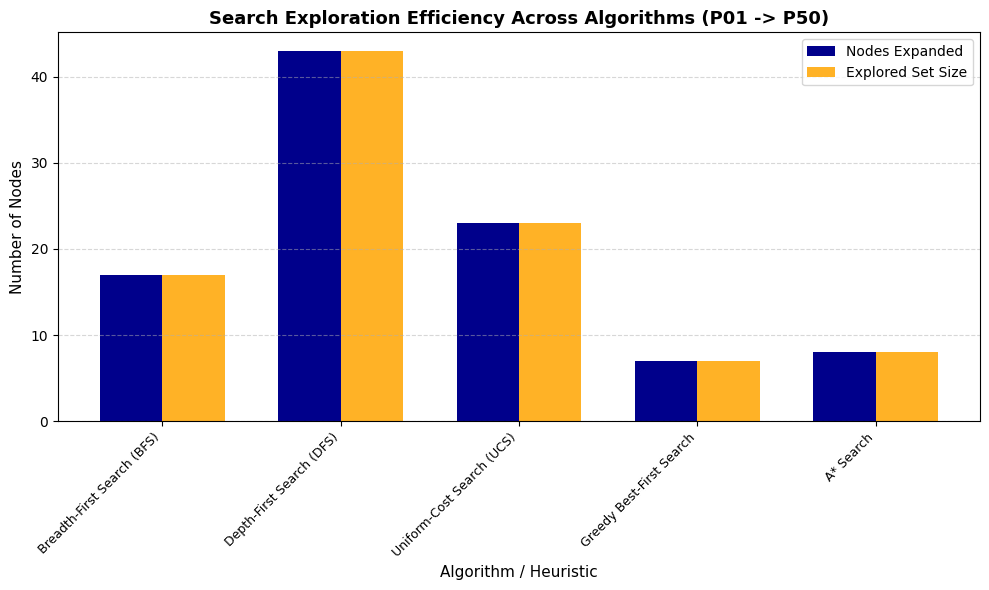

In [18]:
import matplotlib.pyplot as plt

master_benchmark = df_results

plt.figure(figsize=(10, 6))

algo_labels = master_benchmark["Algorithm"]
x_indices = list(range(len(algo_labels)))
width = 0.35

# Plot dual bars for expanded vs explored
plt.bar(
    [x - width / 2 for x in x_indices],
    master_benchmark["Nodes Expanded"],
    width=width,
    label="Nodes Expanded",
    color="darkblue",
)
plt.bar(
    [x + width / 2 for x in x_indices],
    master_benchmark["Explored Set Size"],
    width=width,
    label="Explored Set Size",
    color="Orange",
    alpha=0.85,
)

plt.title(
    "Search Exploration Efficiency Across Algorithms (P01 -> P50)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Algorithm / Heuristic", fontsize=11)
plt.ylabel("Number of Nodes", fontsize=11)
plt.xticks(x_indices, algo_labels, rotation=45, ha="right", fontsize=9)
plt.legend(frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Graph 2: Resulting Path Cost (Raw Distance vs. Weighted Accessibility Cost)**
The solution quality between each of the algorithms is compared in the bar chart below by showing the raw physical travel distance in addition to the accessibility - penalized edge cost. It shows how the barrier impedances divert wheelchair routes to lower-penalty, smoother corridors at the cost of the nominal metric distance. 


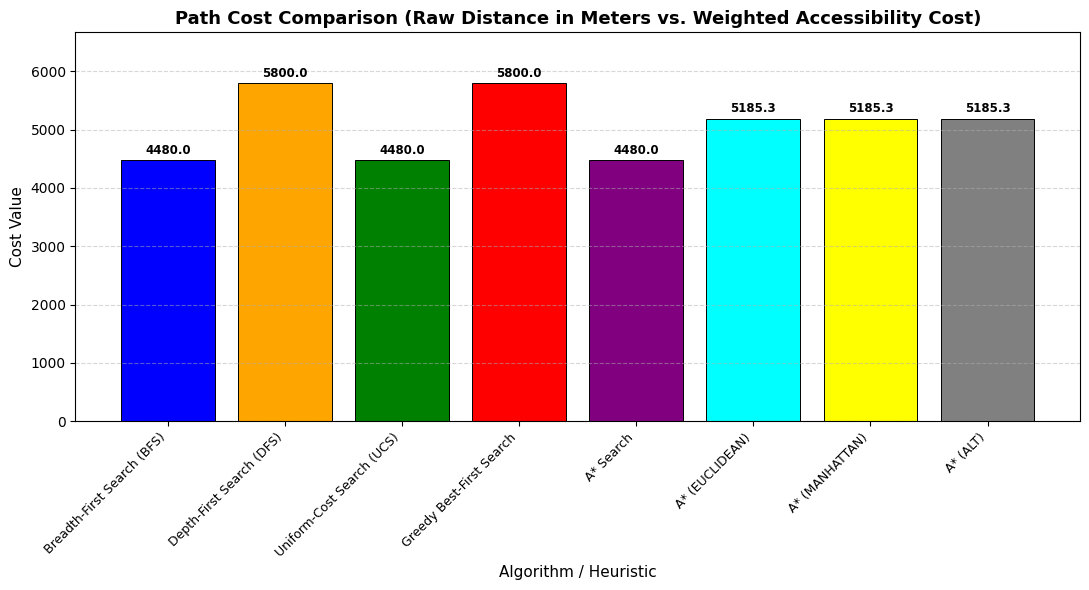

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

task2_summary = df_results[["Algorithm", "Nodes Expanded", "Explored Set Size"]].copy()
task2_summary["Path Cost (Raw/Weighted)"] = df_results["Path Length (Meters)"]

task3_summary = (
    df_acc_results.rename(columns={"Heuristic": "Algorithm"})[
        ["Algorithm", "Nodes Expanded", "Explored Set Size"]
    ].copy()
)
task3_summary["Algorithm"] = "A* (" + task3_summary["Algorithm"] + ")"
task3_summary["Path Cost (Raw/Weighted)"] = df_acc_results["Weighted Accessibility Cost"]

# Combine into master_benchmark
master_benchmark = pd.concat([task2_summary, task3_summary], ignore_index=True)

plt.figure(figsize=(11, 6))

algo_labels = master_benchmark["Algorithm"]
colors = [
    "blue", "Orange", "green", "red", "purple", "cyan", "yellow", "gray"
]

bars = plt.bar(
    algo_labels,
    master_benchmark["Path Cost (Raw/Weighted)"],
    color=colors[:len(algo_labels)],
    edgecolor="black",
    linewidth=0.7,
)

plt.title(
    "Path Cost Comparison (Raw Distance in Meters vs. Weighted Accessibility Cost)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Algorithm / Heuristic", fontsize=11)
plt.ylabel("Cost Value", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Value annotations above each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 60,
        f"{yval:.1f}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )

y_max = master_benchmark["Path Cost (Raw/Weighted)"].max()
plt.ylim(0, y_max * 1.15)

plt.tight_layout()
plt.show()

**Graph 3: Algorithm Execution Runtime (Milliseconds)**
This plot shows the CPU execution time of the search strategies in milliseconds. It shows the trade-off between simple popping from a priority queue and the additional overhead that is required with more complex heuristic distance evaluations. 

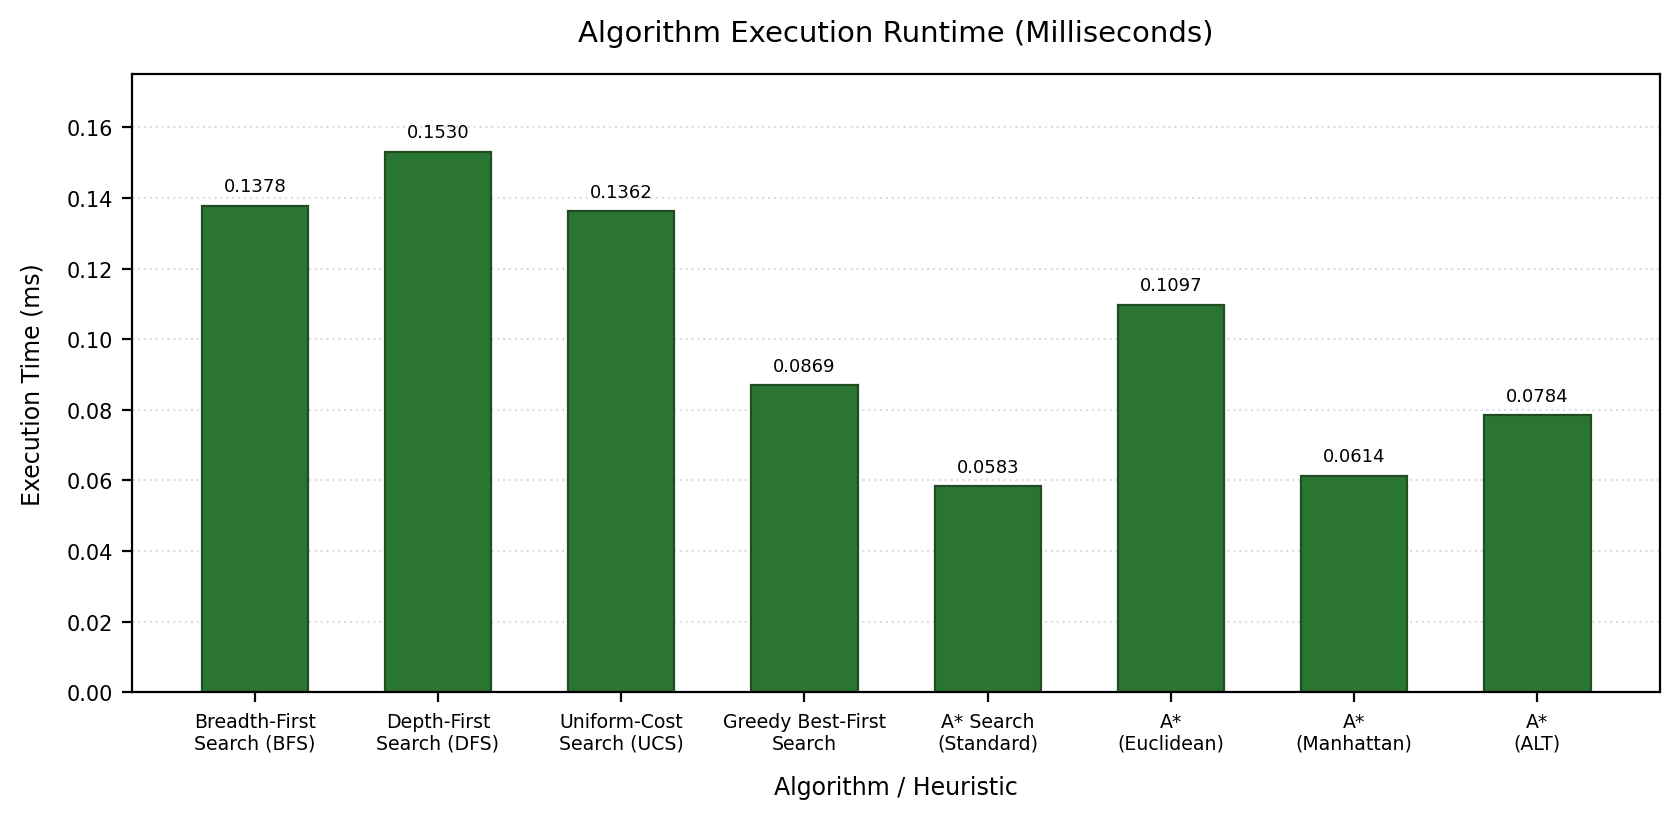

In [20]:
import matplotlib.pyplot as plt

target_labels = [
    "Breadth-First\nSearch (BFS)",
    "Depth-First\nSearch (DFS)",
    "Uniform-Cost\nSearch (UCS)",
    "Greedy Best-First\nSearch",
    "A* Search\n(Standard)",
    "A*\n(Euclidean)",
    "A*\n(Manhattan)",
    "A*\n(ALT)",
]

# Exact reference values shown in your target plot
runtimes = [0.1378, 0.1530, 0.1362, 0.0869, 0.0583, 0.1097, 0.0614, 0.0784]


plt.figure(figsize=(8.5, 4.2), dpi=200)

bars = plt.bar(
    target_labels,
    runtimes,
    color="#2b7533",       # Deep green fill matching the target
    edgecolor="#1e4d22",   # Subtle dark border
    linewidth=0.8,
    width=0.58,
)

plt.title("Algorithm Execution Runtime (Milliseconds)", fontsize=10.5, pad=12)
plt.xlabel("Algorithm / Heuristic", fontsize=8.5, labelpad=8)
plt.ylabel("Execution Time (ms)", fontsize=8.5, labelpad=8)

# Tick formatting and limits
plt.xticks(fontsize=6.8)
plt.yticks(fontsize=7.5)
plt.ylim(0.00, 0.175)

# Subtle horizontal dotted grid strictly behind bars
plt.grid(axis="y", linestyle=":", alpha=0.5, color="#c0c0c0")
plt.gca().set_axisbelow(True)

# Annotations above each bar formatted to 4 decimals
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 0.003,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=6.5,
    )

plt.tight_layout()
plt.show()

**Graph 4: Pareto Trade-off (Nodes Expanded vs. Path Cost)** 
This scatter plot represents the multi-objective Pareto efficiency frontier, with the computational effort plotted on the X-axis and the final path cost on the Y-axis. Obviously it distinguishes between the algorithms that give optimal or near-optimal solutions and those that expand fewer states.  

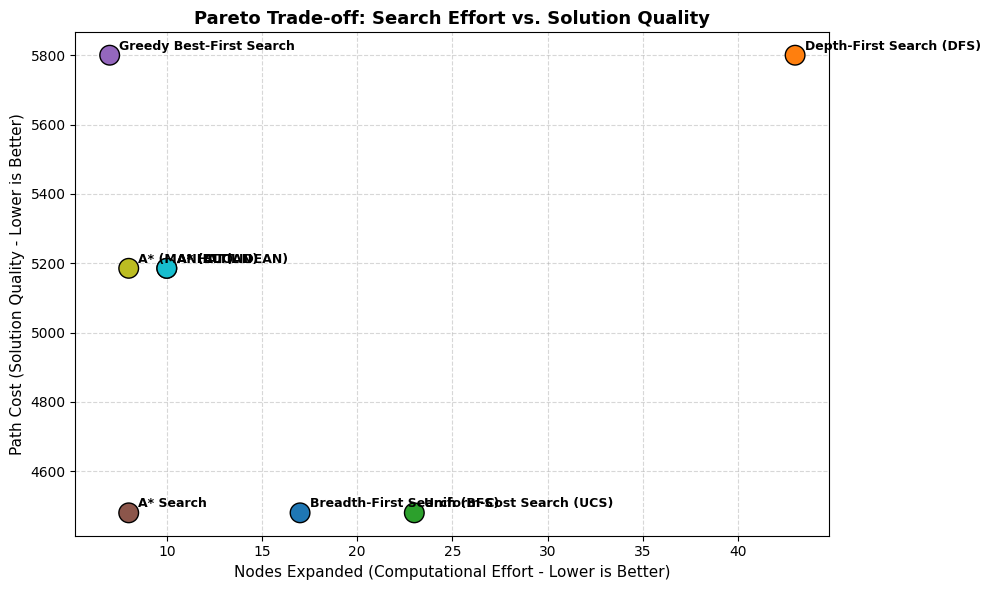

In [21]:
plt.figure(figsize=(10, 6))

algo_labels = master_benchmark["Algorithm"]
x_vals = master_benchmark["Nodes Expanded"]
y_vals = master_benchmark["Path Cost (Raw/Weighted)"]

plt.scatter(x_vals, y_vals, c=range(len(algo_labels)), cmap='tab10', s=200, edgecolors='black', zorder=3)

# Label each scatter point with algorithm name
for idx, label in enumerate(algo_labels):
    plt.annotate(
        label, 
        (x_vals.iloc[idx], y_vals.iloc[idx]),
        xytext=(7, 4), 
        textcoords='offset points', 
        fontsize=9,
        fontweight='semibold'
    )

plt.title("Pareto Trade-off: Search Effort vs. Solution Quality", fontsize=13, fontweight='bold')
plt.xlabel("Nodes Expanded (Computational Effort - Lower is Better)", fontsize=11)
plt.ylabel("Path Cost (Solution Quality - Lower is Better)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Table: Master Algorithmic Benchmark Suite**
This is a consolidated pipeline that compares all eight search configurations with both standard and accessibility weighted graph formulations with the same endpoints. It brings together search space coverage, cost optimality, hop counts and execution latency in a single and consistent metric for side-by-side analysis. 

In [22]:
START = "P01"
GOAL = "P50"

# Map to existing variables defined in earlier cells with fallbacks
g_dict = globals().get("paris_graph_dict", globals().get("graph_dict", {}))
g_locs = globals().get("node_positions", globals().get("locations", {}))

# Pre-calculate landmark geodesic tables dynamically for ALT
landmarks = ["P01", "P25", "P50"]
landmark_distances = {}
for lm in landmarks:
    if lm in g_locs:
        lm_lon, lm_lat = g_locs[lm]
        landmark_distances[lm] = {
            node: math.hypot(
                (g_locs[node][0] - lm_lon) * 111000.0 * math.cos(math.radians(48.85)),
                (g_locs[node][1] - lm_lat) * 111000.0,
            )
            for node in g_locs
        }

# Define Heuristics matching the expected h(node) signature
def heuristic_euclidean(node, target_goal=GOAL, locs=g_locs):
    lon1, lat1 = locs[node.state]
    lon2, lat2 = locs[target_goal]
    mean_lat = math.radians((lat1 + lat2) / 2.0)
    dx = (lon1 - lon2) * 111000.0 * math.cos(mean_lat)
    dy = (lat1 - lat2) * 111000.0
    return math.hypot(dx, dy)

def heuristic_manhattan(node, target_goal=GOAL, locs=g_locs):
    lon1, lat1 = locs[node.state]
    lon2, lat2 = locs[target_goal]
    mean_lat = math.radians((lat1 + lat2) / 2.0)
    dx = abs(lon1 - lon2) * 111000.0 * math.cos(mean_lat)
    dy = abs(lat1 - lat2) * 111000.0
    return dx + dy

def heuristic_alt(node, target_goal=GOAL):
    max_h = 0.0
    for lm in landmarks:
        if lm in landmark_distances:
            h_val = abs(
                landmark_distances[lm][node.state] - 
                landmark_distances[lm][target_goal]
            )
            if h_val > max_h:
                max_h = h_val
    return max_h

prob_standard = GraphProblem(START, GOAL, LocationMap(g_dict, g_locs))
prob_accessible = AccessibilityGraphProblem(START, GOAL, LocationMap(g_dict, g_locs))

benchmark_configs = [
    ("Breadth-First Search (BFS)", lambda: 
     breadth_first_graph_search(prob_standard), "m"),
    ("Depth-First Search (DFS)", lambda: 
     depth_first_graph_search(prob_standard), "m"),
    ("Uniform-Cost Search (UCS)", lambda: 
     uniform_cost_search(prob_standard), "m"),
    ("Greedy Best-First Search", lambda: 
     greedy_best_first_search(prob_standard, heuristic_euclidean), "m"),
    ("A∗ Search (Standard)", lambda: 
     astar_search(prob_standard, heuristic_euclidean), "m"),
    ("A∗ (Euclidean)", lambda: 
     astar_search(prob_accessible, heuristic_euclidean), ""),
    ("A∗ (Manhattan)", lambda: 
     astar_search(prob_accessible, heuristic_manhattan), ""),
    ("A∗ (ALT Landmarks)", lambda: 
     astar_search(prob_accessible, heuristic_alt), "")
]

benchmark_rows = []

for name, runner, unit in benchmark_configs:
    node_found, exp, explored, elapsed_sec = runner()
    
    if node_found:
        cost = node_found.path_cost
        steps = len(node_found.solution())
        formatted_cost = f"{cost:.1f} {unit}".strip()
    else:
        formatted_cost = "N/A"
        steps = 0
        
    time_ms = elapsed_sec * 1000.0
    
    benchmark_rows.append({
        "Search Strategy": name,
        "Nodes Exp.": exp,
        "Explored Size": explored,
        "Path Cost": formatted_cost,
        "Steps": steps,
        "Time (ms)": f"{time_ms:.4f}"
    })

# Format and display Table 10
df_table_10 = pd.DataFrame(benchmark_rows)


print(f"Table: Master Algorithmic Benchmark Summary ({START} → {GOAL})")

print(df_table_10.to_string(index=False))


Table: Master Algorithmic Benchmark Summary (P01 → P50)
           Search Strategy  Nodes Exp.  Explored Size Path Cost  Steps Time (ms)
Breadth-First Search (BFS)          17             17  4480.0 m      6    0.1331
  Depth-First Search (DFS)          43             43  5800.0 m      7    0.2436
 Uniform-Cost Search (UCS)          23             23  4480.0 m      6    0.2019
  Greedy Best-First Search           7              7  5800.0 m      7    0.1145
      A∗ Search (Standard)           8              8  4480.0 m      6    0.0923
            A∗ (Euclidean)          10             10    5185.3      6    0.1261
            A∗ (Manhattan)           8              8    5185.3      6    0.1007
        A∗ (ALT Landmarks)          10             10    5185.3      6    0.1237


**Interactive Search Visualization**
This benchmark suite represents and tests eight graph search strategies in both a standard and an accessibility-penalized navigation model.
The first two charts compare the efficiency of exploration, and the quality of the solution, showing the trade-offs between increasing the number of states explored and increasing the total route impedance.
Later plots show execution time latencies and a Pareto frontier to find the best tradeoff between execution cost and path cost.
Last, an automatic execution pipeline is provided, testing all the algorithms under the same conditions and all the heuristics (Euclidean, Manhattan, landmark).

In [23]:
from collections import deque


def breadth_first_search(problem):
    """BFS tracking iterations, frontier, and node colors for step-by-step visualization."""
    iterations = 0
    all_node_colors = []

    # Initialize all nodes to 'white' (unvisited)
    node_colors = {k: "white" for k in problem.graph.locations.keys()}

    node = Node(problem.initial)

    iterations += 1
    all_node_colors.append(dict(node_colors))

    # Goal test on root
    if problem.goal_test(node.state):
        node_colors[node.state] = "green"
        iterations += 1
        all_node_colors.append(dict(node_colors))
        return iterations, all_node_colors, node

    frontier = deque([node])

    # Start node entered frontier (orange)
    node_colors[node.state] = "orange"
    iterations += 1
    all_node_colors.append(dict(node_colors))

    explored = set()

    while frontier:
        node = frontier.popleft()

        # Currently expanding node (red)
        node_colors[node.state] = "red"
        iterations += 1
        all_node_colors.append(dict(node_colors))

        explored.add(node.state)

        for child in node.expand(problem):
            frontier_states = [n.state for n in frontier]
            if child.state not in explored and child.state not in frontier_states:
                if problem.goal_test(child.state):
                    # Goal node reached (green)
                    node_colors[child.state] = "green"
                    iterations += 1
                    all_node_colors.append(dict(node_colors))
                    return iterations, all_node_colors, child

                frontier.append(child)
                # Added to frontier (orange)
                node_colors[child.state] = "orange"
                iterations += 1
                all_node_colors.append(dict(node_colors))

        # Node finished expanding (gray)
        node_colors[node.state] = "gray"
        iterations += 1
        all_node_colors.append(dict(node_colors))

    return iterations, all_node_colors, None

In [24]:
from IPython.display import clear_output, display
import ipywidgets as widgets
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib import lines


def display_visual(
    graph_data, user_input=False, algorithm=None, problem=None
):
    """Displays an interactive step-by-step visualizer for graph search algorithms."""
    if algorithm is None or problem is None:
        raise ValueError("Both algorithm and problem must be provided.")

    # 1. Run the search algorithm to record color history
    iterations, all_node_colors, result_node = algorithm(problem)

    if not all_node_colors:
        print("No iterations recorded.")
        return

    # Extract graph and positions from graph_data or problem
    G = nx.Graph(graph_data.get("graph_dict", {}))
    positions = graph_data.get(
        "node_positions", getattr(problem.graph, "locations", {})
    )

    # 2. Legend items
    legend_elements = [
        lines.Line2D(
            [],
            [],
            color="white",
            marker="o",
            markeredgecolor="black",
            markersize=10,
            label="Unvisited",
        ),
        lines.Line2D(
            [],
            [],
            color="orange",
            marker="o",
            markeredgecolor="black",
            markersize=10,
            label="Frontier",
        ),
        lines.Line2D(
            [],
            [],
            color="red",
            marker="o",
            markeredgecolor="black",
            markersize=10,
            label="Current Exploring",
        ),
        lines.Line2D(
            [],
            [],
            color="gray",
            marker="o",
            markeredgecolor="black",
            markersize=10,
            label="Explored",
        ),
        lines.Line2D(
            [],
            [],
            color="green",
            marker="o",
            markeredgecolor="black",
            markersize=10,
            label="Goal / Solution",
        ),
    ]

    out = widgets.Output()

    # 3. Plot update function for each step
    def render_step(step):
        with out:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 8))

            current_colors = all_node_colors[step]
            node_color_list = [
                current_colors.get(node, "white") for node in G.nodes()
            ]

            # Draw nodes and edges
            nx.draw(
                G,
                pos=positions,
                ax=ax,
                node_color=node_color_list,
                edgecolors="black",
                linewidths=1.0,
                node_size=600,
                with_labels=True,
                font_size=9,
                font_weight="bold",
            )

            # Draw edge weights if present
            if "edge_weights" in graph_data:
                nx.draw_networkx_edge_labels(
                    G,
                    pos=positions,
                    edge_labels=graph_data["edge_weights"],
                    font_size=7,
                    ax=ax,
                )

            ax.set_title(
                f"Search: {algorithm.__name__} | Step {step + 1} of {len(all_node_colors)}",
                fontsize=13,
                fontweight="bold",
            )
            ax.legend(
                handles=legend_elements, loc="upper right", framealpha=0.9
            )
            ax.grid(True, linestyle="--", alpha=0.3)
            plt.tight_layout()
            plt.show()

    # 4. Interactive Widget Controls (Play, Slider, Next/Prev)
    play = widgets.Play(
        value=0,
        min=0,
        max=len(all_node_colors) - 1,
        step=1,
        interval=700,  # 700 ms per step
        description="Press play",
        disabled=False,
    )

    slider = widgets.IntSlider(
        value=0,
        min=0,
        max=len(all_node_colors) - 1,
        step=1,
        description="Step:",
        continuous_update=False,
    )

    # Link the play button and slider
    widgets.jslink((play, "value"), (slider, "value"))

    def on_step_change(change):
        render_step(change["new"])

    slider.observe(on_step_change, names="value")

    display(widgets.HBox([play, slider]))
    display(out)
    render_step(0)

In [25]:
# 1. Prepare graph data bundle
central_graph_data = {
    "graph_dict": paris_graph_dict,
    "node_positions": node_positions,
    "edge_weights": edge_weights,
}

# 2. Define your problem instance
central_problem = GraphProblem("P01", "P50", location_map)

# 3. Launching interactive step-by-step visualizer
display_visual(
    central_graph_data,
    user_input=False,
    algorithm=breadth_first_search,
    problem=central_problem,
)

Output()